# Airbag CAD-to-CAE Volume Prediction using Convolutional Neural Networks

This project focuses on developing a Convolutional Neural Network (CNN) to predict airbag volume directly from grayscale CAD images paired with engineering simulation data. Using a dataset of approximately 60,000 airbag images paired with corresponding volume values, the model learns visual patterns in engineering designs and maps them to continuous numerical predictions.

The model learns visual patterns from airbag designs to estimate volume as a continuous numerical output, connecting Computer-Aided Design (CAD) with data-driven engineering prediction.

The workflow covers image preprocessing, data augmentation, custom PyTorch dataset development, CNN architecture design, GPU-accelerated training, and evaluation using MAE, RMSE, and R².

**Goal:** Evaluate the effectiveness of CNN-based regression for airbag volume prediction, demonstrating the potential of deep learning to accelerate engineering design evaluation and support CAD-to-CAE workflows.

In [1]:
# Importing Libraries
import os
import random
from tqdm.auto import tqdm
from pathlib import Path
import time

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torchvision
import torch.optim as optim
import torchvision.transforms as transforms
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import cv2
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2


C:\Users\dell\ai-gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
## Reproducibility
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
random.seed(seed)
np.random.seed(seed)

In [3]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

## Data Retrival

In [4]:
ROOT_DIR = "./air_bag_data"

# Check if the directory exists
if os.path.exists(ROOT_DIR):
    print("The directory exists!")
else:
    print("The directory does not exist.")

The directory exists!


In [5]:
CSV_PATH = os.path.join(ROOT_DIR, "60k labels.csv")
IMG_DIR = os.path.join(ROOT_DIR, "60k_png_1200x900")

df_raw = pd.read_csv(CSV_PATH, header=None)

In [6]:
# 2. Keep both the ID column and the Volume column (the last two columns)
df_clean = df_raw.iloc[:, -2:].copy()
df_clean.columns = ['img_id', 'volume']

In [7]:
df_clean['image_name'] = "IC" + df_clean['img_id'].astype(int).astype(str) + ".png"

# Keeping only what we need
df = df_clean[['image_name', 'volume']]

print("--- Cleaned Mapping Data ---")
print(df.head())

--- Cleaned Mapping Data ---
  image_name  volume
0    IC1.png   24.04
1    IC2.png   40.44
2    IC3.png   30.24
3    IC4.png   26.35
4    IC5.png   29.55


## Exploratory Data Analysis

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   image_name  60000 non-null  str    
 1   volume      60000 non-null  float64
dtypes: float64(1), str(1)
memory usage: 937.6 KB


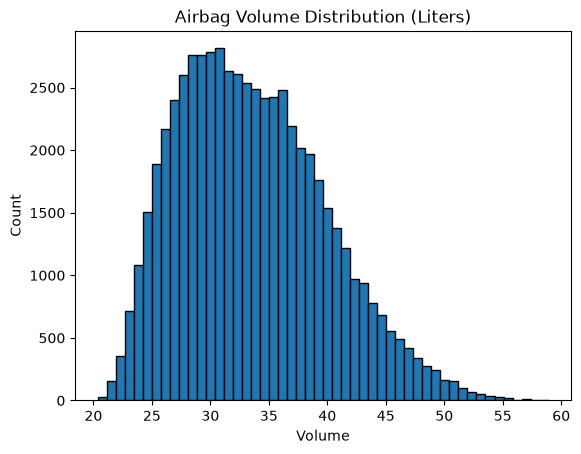

In [9]:
# Visualize the volume distribution to check for skewness or outliers
plt.hist(df['volume'], bins=50, edgecolor='black')
plt.title('Airbag Volume Distribution (Liters)')
plt.xlabel('Volume')
plt.ylabel('Count')
plt.savefig("images/airbag_volume_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
df['volume'].skew()

np.float64(0.5043937093922177)

## Data Preporcessing and Prepration

### For Target

In [11]:
# Split into 70% Train, 15% Val, 15% Test
train_val_df, test_df = train_test_split(df, test_size=0.15, random_state=42)
train_df, val_df = train_test_split(train_val_df, test_size=0.1765, random_state=42)

print(f"Train size: {len(train_df)} | Val size: {len(val_df)} | Test size: {len(test_df)}")


Train size: 41998 | Val size: 9002 | Test size: 9000


### Dynamic Image Retrieval & Transforms

In [12]:
train_transforms = A.Compose([
    A.Resize(224, 224),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=10, p=0.5, border_mode=cv2.BORDER_CONSTANT),
    A.Normalize(mean=(0.5,), std=(0.5,)),
    ToTensorV2()
])

val_test_transforms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.5,), std=(0.5,)),
    ToTensorV2()
])

C:\Users\dell\ai-gpu\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [13]:
class AirbagCADDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform
        
        # Convert columns to fast numpy arrays up front
        self.image_names = dataframe['image_name'].values
        self.volumes = dataframe['volume'].values

    def __len__(self):
        return len(self.volumes)

    def __getitem__(self, idx):
        # Grab the true filename tracked from the CSV row
        img_name = self.image_names[idx]
        img_path = os.path.join(self.img_dir, img_name)
        
        # Diagnostic check to catch path issues
        if not os.path.exists(img_path):
            raise FileNotFoundError(
                f"\n[PATH ERROR] Cannot find image on disk!\n"
                f"Looking for: {img_name}\n"
                f"At path: {os.path.abspath(img_path)}"
            )
        
        # Load image
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        if self.transform:
            augmented = self.transform(image=image)
            image = augmented['image']
            
        target = float(self.volumes[idx])
            
        return image, torch.tensor(target, dtype=torch.float32)

In [14]:
train_dataset = AirbagCADDataset(dataframe=train_df, img_dir=IMG_DIR, transform=train_transforms)
val_dataset   = AirbagCADDataset(dataframe=val_df, img_dir=IMG_DIR, transform=val_test_transforms)
test_dataset  = AirbagCADDataset(dataframe=test_df, img_dir=IMG_DIR, transform=val_test_transforms)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0, pin_memory=True)

print("Running sanity check...")
images, targets = next(iter(train_loader))
print("--- DataLoader Batch Construction Verified ---")
print(f"Batch Image Matrix Shape: {images.shape}")   
print(f"Batch Target Vector Shape: {targets.shape}")  

Running sanity check...
--- DataLoader Batch Construction Verified ---
Batch Image Matrix Shape: torch.Size([64, 1, 224, 224])
Batch Target Vector Shape: torch.Size([64])


## Defining and Training Model 

In [15]:
class AirbagCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=32,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=64,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=128,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # REGRESSION HEAD
       
        self.regressor = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
        

    def forward(self, x):

        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)

        x = self.regressor(x)

        return x

In [16]:
model = AirbagCNN().to(device)

In [17]:
device = next(model.parameters()).device
print(device)  

cuda:0


In [18]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [19]:
torch.manual_seed(42)

epochs = 2

train_losses = []
val_losses = []

total_train_start = time.time()

for epoch in range(epochs):

    # TRAINING
    model.train()
    running_train_loss = 0.0

    train_start = time.time()

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{epochs} [Train]",
        leave=True
    )

    for images, targets in train_bar:

        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True).view(-1, 1)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

        train_bar.set_postfix(loss=f"{loss.item():.6f}")

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    train_time = time.time() - train_start

    # VALIDATION
    model.eval()
    running_val_loss = 0.0

    val_start = time.time()

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch + 1}/{epochs} [Validation]",
        leave=True
    )

    with torch.no_grad():

        for images, targets in val_bar:

            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True).view(-1, 1)

            outputs = model(images)
            val_loss = criterion(outputs, targets)

            running_val_loss += val_loss.item() * images.size(0)

            val_bar.set_postfix(loss=f"{val_loss.item():.6f}")

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    val_time = time.time() - val_start

    # EPOCH SUMMARY
    print(f"\nEpoch [{epoch + 1}/{epochs}]")
    print(f"Train Loss: {epoch_train_loss:.6f}")
    print(f"Validation Loss: {epoch_val_loss:.6f}")
    print(f"Training Time: {train_time:.2f} seconds")
    print(f"Validation Time: {val_time:.2f} seconds")
    print(f"Combined Epoch Time: {train_time + val_time:.2f} seconds")
    print("-" * 50)

total_train_time = time.time() - total_train_start

print("\n--- TRAINING FINISHED ---")
print(f"Total time for {epochs} epochs: {total_train_time / 60:.2f} minutes")

Epoch 1/2 [Validation]: 100%|██████████| 141/141 [00:42<00:00,  3.35it/s, loss=5.053684]



Epoch [1/2]
Train Loss: 62.794351
Validation Loss: 3.612530
Training Time: 298.02 seconds
Validation Time: 42.12 seconds
Combined Epoch Time: 340.14 seconds
--------------------------------------------------


Epoch 2/2 [Validation]: 100%|██████████| 141/141 [00:37<00:00,  3.78it/s, loss=6.060082]


Epoch [2/2]
Train Loss: 4.439589
Validation Loss: 4.782212
Training Time: 278.77 seconds
Validation Time: 37.35 seconds
Combined Epoch Time: 316.12 seconds
--------------------------------------------------

--- TRAINING FINISHED ---
Total time for 2 epochs: 10.94 minutes


## Model Evaluation

In [20]:
model.eval()

all_predictions = []
all_targets = []

test_start = time.time()

test_bar = tqdm(
    test_loader,
    desc="Testing Airbag CNN",
    leave=True
)

with torch.no_grad():

    for images, targets in test_bar:

        images = images.to(device)
        targets = targets.to(device).view(-1, 1)

        outputs = model(images)

        all_predictions.extend(outputs.cpu().numpy().flatten())
        all_targets.extend(targets.cpu().numpy().flatten())

        test_bar.set_postfix(samples=len(all_targets))

test_time = time.time() - test_start

# Calculate regression metrics
mae = mean_absolute_error(all_targets, all_predictions)
mse = mean_squared_error(all_targets, all_predictions)
rmse = mse ** 0.5
r2 = r2_score(all_targets, all_predictions)

print("\n--- TEST RESULTS ---")
print(f"Test samples: {len(all_targets)}")
print(f"MAE: {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R² Score: {r2:.6f}")
print(f"Total test time: {test_time:.2f} seconds")
print(f"Total test time: {test_time / 60:.2f} minutes")

print("\n--- FIRST 10 PREDICTIONS ---")

for i in range(min(10, len(all_targets))):
    print(
        f"Actual: {all_targets[i]:.4f} | "
        f"Predicted: {all_predictions[i]:.4f}"
    )

Testing Airbag CNN: 100%|██████████| 141/141 [00:42<00:00,  3.32it/s, samples=9000]


--- TEST RESULTS ---
Test samples: 9000
MAE: 1.750074
RMSE: 2.237501
R² Score: 0.872768
Total test time: 42.43 seconds
Total test time: 0.71 minutes

--- FIRST 10 PREDICTIONS ---
Actual: 26.7400 | Predicted: 24.8377
Actual: 40.7700 | Predicted: 38.3920
Actual: 26.1900 | Predicted: 24.9839
Actual: 28.4900 | Predicted: 28.2075
Actual: 30.2000 | Predicted: 31.4689
Actual: 27.5800 | Predicted: 27.8522
Actual: 32.7100 | Predicted: 30.5754
Actual: 27.7000 | Predicted: 28.3210
Actual: 33.5100 | Predicted: 30.4033
Actual: 30.9700 | Predicted: 31.0191


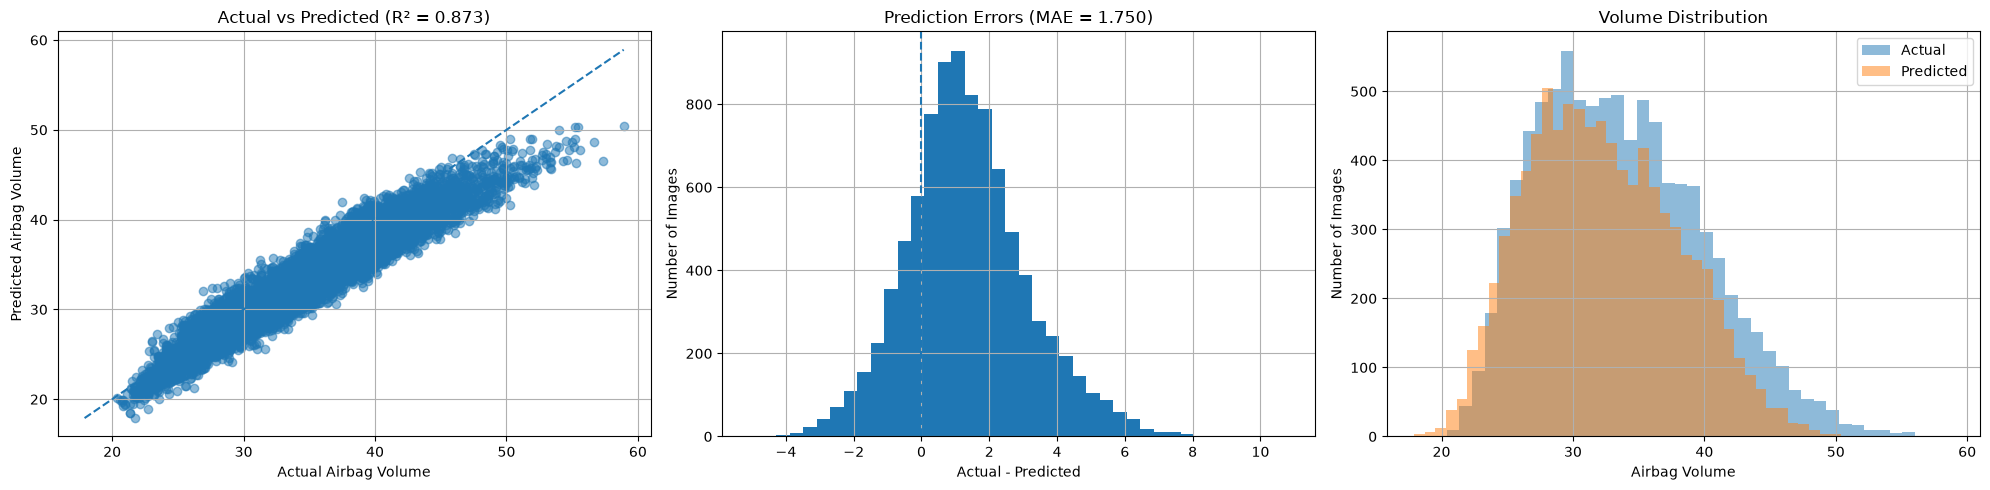

In [21]:
# Prediction Visualization
# Convert predictions and actual values to NumPy arrays
y_pred = np.array(all_predictions).reshape(-1)
y_true = np.array(all_targets).reshape(-1)

# Calculate errors
errors = y_true - y_pred

# Calculate metrics
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

# Create 3 visualization graphs
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Actual vs Predicted
axes[0].scatter(y_true, y_pred, alpha=0.5)
minimum = min(y_true.min(), y_pred.min())
maximum = max(y_true.max(), y_pred.max())

axes[0].plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)
axes[0].set_title(f"Actual vs Predicted (R² = {r2:.3f})")
axes[0].set_xlabel("Actual Airbag Volume")
axes[0].set_ylabel("Predicted Airbag Volume")
axes[0].grid(True)

# 2. Prediction Errors
axes[1].hist(errors, bins=40)
axes[1].axvline(0, linestyle="--")
axes[1].set_title(f"Prediction Errors (MAE = {mae:.3f})")
axes[1].set_xlabel("Actual - Predicted")
axes[1].set_ylabel("Number of Images")
axes[1].grid(True)

# 3. Actual vs Predicted Distribution
axes[2].hist(y_true, bins=40, alpha=0.5, label="Actual")
axes[2].hist(y_pred, bins=40, alpha=0.5, label="Predicted")
axes[2].set_title("Volume Distribution")
axes[2].set_xlabel("Airbag Volume")
axes[2].set_ylabel("Number of Images")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.savefig("images/airbag_prediction_visualization.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion

This project demonstrates a CNN-based regression approach for predicting airbag volume directly from grayscale CAD images, connecting computer vision with engineering design analysis.

### Key Results

1. **Strong Predictive Performance:** Achieved an R² score of **0.8728**, explaining approximately 87.3% of the variation in airbag volume across 9,000 unseen test samples.
2. **Low Prediction Error:** Obtained an MAE of **1.7501** and an RMSE of **2.2375**, demonstrating promising accuracy in estimating airbag volume.
3. **Deep Learning Pipeline:** Implemented image preprocessing, data augmentation, a custom PyTorch dataset, CNN architecture, GPU-accelerated training, validation, and testing.
4. **Visual Evaluation:** Analyzed actual-versus-predicted values, prediction error distributions, and volume distributions to assess model behavior.
5. **Engineering Application:** Demonstrated the potential of image-based deep learning to estimate engineering quantities from CAD designs and support faster preliminary design evaluation.

### Final Evaluation Metrics

| Metric | Result |
|---|---:|
| Test Samples | 9,000 |
| MAE | 1.7501 |
| RMSE | 2.2375 |
| R² Score | 0.8728 |
| Test Evaluation Time | 42.43 seconds |
| Training Epochs | 2 |

The model achieved promising predictive performance, with an R² score of approximately 0.873. The results suggest that a CNN can learn useful visual features from airbag CAD images to estimate volume without requiring a separate manual feature-extraction process.

The existing visualization figures remain useful for interpreting the new results. However, the displayed metric values in the plots should be regenerated from the latest predictions if they are hard-coded or were saved from an earlier run.

**Limitations and Future Work:** Further experiments with hyperparameter tuning, additional training epochs, improved generalization, and validation on different airbag designs could improve reliability. The model should be treated as a predictive surrogate for preliminary evaluation, not a replacement for engineering simulation or physical validation.

**Reproducibility Note:** Results can vary between runs because of random initialization, data shuffling, augmentation, and GPU nondeterminism. The reported metrics correspond to this particular evaluated model run.